## 📊 Chest X-Ray AI Classification Demo (Gemma-3 VLM)
This notebook demonstrates how to load, run, and evaluate a state-of-the-art **Vision-Language Model (Gemma-3-4b)** fine-tuned for classifying Chest X-Rays into **Normal** or **Pneumonia**.

---


### 📋 Quick Setup Instructions
* Run the installation cell below **once**.
* Click **"Restart session"** at the bottom of the output when it completes.
* Do not run the setup cell again after restarting. Go to the next cell.

In [1]:
import os
# Check if running in a Colab environment with GPU
if "COLAB_GPU" in os.environ:
    # Use unsloth[colab-new] for Colab to handle all dependencies.
    # This ensures compatible versions of bitsandbytes, accelerate, xformers, peft, trl, transformers etc.
    # We explicitly specify the unsloth version requested by the original code.
    !pip install "unsloth[colab-new]==2026.1.3"
else:
    # For non-Colab environments or if no GPU, install basic unsloth.
    !pip install "unsloth==2026.1.3"

# Note: The original code also had specific versions for transformers and trl.
# However, unsloth[colab-new] typically installs compatible versions automatically.
# If these specific versions are strictly required and cause issues after this change,
# they might need to be addressed separately or through unsloth's own configuration.
# For now, relying on unsloth[colab-new] is the most robust approach.

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.6/66.6 kB 635.4 kB/s eta 0:00:00 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.9 MB/s eta 0:00:00
INFO: pip is looking at multiple versions of diffusers to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 389.2/389.2 kB 2.5 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 35.3 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 506.8/506.8 kB 44.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 42.6 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 43.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 kB 44.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 97.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 113.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━

### 📥 Model Loading
* This step loads the 4-bit optimized **Gemma-3-4b** Vision-Language Model.
* Click run and wait for it to finish.

In [2]:
 from unsloth import FastVisionModel # FastLanguageModel for LLMs
import torch

model, processor = FastVisionModel.from_pretrained(
    "unsloth/gemma-3-4b-it",
    load_in_4bit = True, # Use 4bit to reduce memory use. False for 16bit LoRA.
    use_gradient_checkpointing = "unsloth", # True or "unsloth" for long context
)
from unsloth import get_chat_template

processor = get_chat_template(
    processor,
    "gemma-3"
)

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.1.3: Fast Gemma3 patching. Transformers: 4.57.3.
   \\   /|    NVIDIA A100-SXM4-40GB. Num GPUs = 1. Max memory: 39.494 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 8.0. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = TRUE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Gemma3 does not support SDPA - switching to fast eager.


model.safetensors:   0%|          | 0.00/4.56G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/210 [00:00<?, ?B/s]

processor_config.json:   0%|          | 0.00/70.0 [00:00<?, ?B/s]

chat_template.json: 0.00B [00:00, ?B/s]

...

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/4.69M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/33.4M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/670 [00:00<?, ?B/s]

### 📂 Dataset Loading
* Downloads the chest X-ray evaluation dataset containing images and clinical ground-truth labels.

In [11]:
from datasets import load_dataset
test_ds = load_dataset(
    "Henryayay/POLCOVID_task1_70_10_20",  # 🔁 CHANGE THIS
    split="test"
)

from pathlib import Path
import os
import pandas as pd
import re

TASK_ID = "Task1_base"
RESULTS_PROJECT_ROOT = Path(
    r"C:\Users\Henryayay\OneDrive - The Hong Kong Polytechnic University\Desktop\AI xray classification project\Results"
)
LOCAL_RESULTS_ROOT = RESULTS_PROJECT_ROOT / "ICL" / "Task1"

def _slug(text):
    text = str(text).strip().replace(" ", "-")
    return re.sub(r"[^A-Za-z0-9._-]+", "_", text)

def record_and_save_run(y_true, y_pred, setup, model, accuracy_pct, task_id=TASK_ID, trigger_download=True):
    """Save predictions under Results/<method>/<task>/ with task, setup, model, and accuracy in the filename."""
    name_to_id = {"Normal": 0, "Pneumonia": 1}
    y_true = list(y_true)
    y_pred = list(y_pred)
    df = pd.DataFrame({
        "Index": range(len(y_true)),
        "True_Label_ID": [name_to_id.get(str(v).strip(), -1) for v in y_true],
        "Predicted_Label_ID": [name_to_id.get(str(v).strip(), -1) for v in y_pred],
        "True_Label_Name": y_true,
        "Predicted_Label_Name": y_pred,
    })

    meta = {
        "task_id": task_id,
        "setup": setup,
        "model": model,
        "accuracy_pct": float(accuracy_pct),
        "y_true": y_true,
        "y_pred": y_pred,
    }
    global RUN_META
    RUN_META = meta
    history = list(globals().get("RUN_HISTORY", []))
    key = (task_id, setup, model)
    history = [r for r in history if (r["task_id"], r["setup"], r["model"]) != key]
    history.append(meta)
    globals()["RUN_HISTORY"] = history

    acc_label = f"{float(accuracy_pct):.2f}pct"
    filename = f"{_slug(task_id)}_{_slug(setup)}_{_slug(model)}_acc{acc_label}.csv"

    # On Colab/Linux, a Windows path like C:\Users\... is NOT absolute, so mkdir
    # would create a relative junk folder in the VM. Only try LOCAL_RESULTS_ROOT
    # when it is a real absolute path on this OS.
    dest_dir = None
    candidates = []
    if LOCAL_RESULTS_ROOT.is_absolute():
        candidates.append(LOCAL_RESULTS_ROOT)
    candidates.append(Path.cwd() / "Results" / "ICL" / "Task1")
    if Path("/content").exists():
        candidates.append(Path("/content/Results/ICL/Task1"))
    for candidate in candidates:
        try:
            candidate.mkdir(parents=True, exist_ok=True)
            probe = candidate / ".write_test"
            probe.write_text("ok", encoding="utf-8")
            probe.unlink()
            dest_dir = candidate
            break
        except Exception:
            continue
    if dest_dir is None:
        dest_dir = Path.cwd() / "Results" / "ICL" / "Task1"
        dest_dir.mkdir(parents=True, exist_ok=True)

    dest_path = dest_dir / filename
    df.to_csv(dest_path, index=False)
    print(f"Saved predictions to: {dest_path}")

    errors = df[df["Predicted_Label_ID"] == -1]
    if len(errors) > 0:
        print(f"WARNING: {len(errors)} predictions could not be mapped to IDs!")
        print(errors["Predicted_Label_Name"].unique())
    else:
        print("Verification Passed: All predictions mapped correctly.")

    in_colab = Path("/content").exists() or bool(os.environ.get("COLAB_RELEASE_TAG"))
    # Only treat as saved on PC when we are actually on Windows AND wrote under the absolute Results root.
    saved_on_pc = False
    if os.name == "nt" and LOCAL_RESULTS_ROOT.is_absolute():
        try:
            saved_on_pc = str(dest_path.resolve()).startswith(str(LOCAL_RESULTS_ROOT.resolve()))
        except Exception:
            saved_on_pc = False
    will_attempt_download = bool(trigger_download and (not saved_on_pc or in_colab))
    if will_attempt_download:
        cwd_copy = Path.cwd() / filename
        try:
            same_file = cwd_copy.resolve() == dest_path.resolve()
        except Exception:
            same_file = False
        if not same_file:
            df.to_csv(cwd_copy, index=False)
        download_target = cwd_copy if cwd_copy.exists() else dest_path
        try:
            from google.colab import files
            print(f"Starting download for {filename}")
            print(f"Save the file into this folder on your PC:\n{LOCAL_RESULTS_ROOT}")
            files.download(str(download_target))
        except Exception as exc:
            print(f"Could not auto-download to your PC ({exc}).")
            print(
                "Copy this Colab file to your PC Results folder:\n"
                f"  source: {download_target.resolve() if download_target.exists() else download_target}\n"
                f"  dest:   {LOCAL_RESULTS_ROOT / filename}"
            )
    return dest_path


### ⚙️ Diagnostic Inference Run
Select **one** of the options below depending on your runtime:
* **Option A (Slow):** For free-tier users. Processes 1 image at a time.
* **Option B (Fast - Recommended):** For premium users. Processes 8 images at once.

#### 🐢 Option A: Sequential Evaluation (One-by-One)
*Use this if you are on Colab's free GPU tier. It will print a live progress bar and display a final performance report once completed.*

In [4]:
# ==========================================
# 1. SETUP & IMPORTS
# ==========================================
# from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
# import seaborn as sns
# import matplotlib.pyplot as plt
# from tqdm import tqdm
# import torch

# # Ensure model is in inference mode (Unsloth method)
# FastVisionModel.for_inference(model)

# # Define your labels again just to be safe
# LABEL_MAP = {
#     0: "Normal",
#     1: "Pneumonia",
# }

# # ==========================================
# # 2. INFERENCE LOOP (Test all 40 images)
# # ==========================================
# y_true = []
# y_pred = []

# print("Starting evaluation on test images...")

# for sample in tqdm(test_ds):
#     # A. Get the actual Label (Ground Truth)
#     actual_label = LABEL_MAP[sample["label"]]
#     y_true.append(actual_label)

#     # B. Prepare the Image & Instruction
#     image = sample["image"]
#     instruction = (
#     "You are an expert radiologist. Analyze this chest X-ray and classify it as 'Normal' or 'Pneumonia'. Output only the diagnosis."
# )

#     messages = [
#         {
#             "role": "user",
#             "content": [
#                 {"type": "text", "text": instruction},
#                 {"type": "image"} # Placeholder
#             ],
#         }
#     ]

#     # C. Process Inputs
#     input_text = processor.apply_chat_template(messages, add_generation_prompt=True)
#     inputs = processor(
#         text=input_text,
#         images=image,
#         add_special_tokens=False,
#         return_tensors="pt"
#     ).to("cuda")

#     # D. Generate Prediction
#     output = model.generate(
#         **inputs,
#         max_new_tokens=30,
#         temperature=0.01,   # Low temp = more strict/consistent
#         use_cache=True
#     )

#     # E. Decode the answer
#     # We slice [:, inputs.input_ids.shape[1]:] to remove the prompt and keep only the answer
#     response = processor.batch_decode(output[:, inputs.input_ids.shape[1]:], skip_special_tokens=True)[0]


#     if "Pneumonia" in response:
#         pred_label = "Pneumonia"
#     elif "Normal" in response:
#         pred_label = "Normal"
#     else:
#         pred_label = "Error"

#     y_pred.append(pred_label)


# # ==========================================
# # CALCULATE METRICS & PLOT
# # ==========================================

# # 1. Calculate Accuracy
# acc = accuracy_score(y_true, y_pred)
# accuracy_pct = acc * 100

# # 2. Print Text Reports
# print(f"\n✅ Base Gemma3 Task1 Accuracy: {accuracy_pct:.2f}%")
# print("\n📊 Detailed Report:")
# print(classification_report(y_true, y_pred, labels=["Normal", "Pneumonia"]))


# # C. Confusion Matrix
# cm = confusion_matrix(y_true, y_pred, labels=["Normal", "Pneumonia"])

# plt.figure(figsize=(6, 5))
# sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
#             xticklabels=["Normal", "Pneumonia"],
#             yticklabels=["Normal", "Pneumonia"])
# plt.xlabel('Predicted by AI')
# plt.ylabel('Actual Truth')
# plt.title('Confusion Matrix')
# plt.show()


#### ⚡ Option B: Batched Evaluation (High Speed)
*Highly recommended for premium GPUs (A100 or L4). Processes images in parallel blocks of 8.*

Starting batched evaluation (Batch Size: 8)...


100%|██████████| 57/57 [01:07<00:00,  1.19s/it]


✅ Batched Gemma3 Task1 Accuracy: 57.02%

📊 Detailed Report:
              precision    recall  f1-score   support

      Normal       0.66      0.29      0.41       228
   Pneumonia       0.55      0.85      0.66       228

    accuracy                           0.57       456
   macro avg       0.60      0.57      0.53       456
weighted avg       0.60      0.57      0.53       456



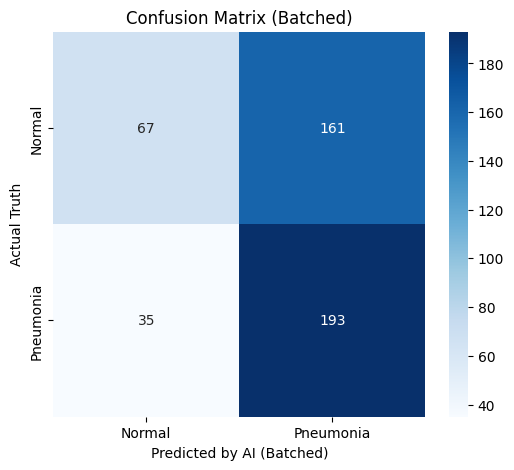

Saved predictions to: C:\Users\Henryayay\OneDrive - The Hong Kong Polytechnic University\Desktop\AI xray classification project\Results/ICL/Task1/Task1_base_base_batched_gemma-3-4b-it_acc57.02pct.csv
Verification Passed: All predictions mapped correctly.


PosixPath('C:\\Users\\Henryayay\\OneDrive - The Hong Kong Polytechnic University\\Desktop\\AI xray classification project\\Results/ICL/Task1/Task1_base_base_batched_gemma-3-4b-it_acc57.02pct.csv')

In [12]:
from torch.utils.data import DataLoader
import torch
from tqdm import tqdm
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from unsloth import FastVisionModel

# Define the labels used in the dataset mapping
LABEL_MAP = {
    0: "Normal",
    1: "Pneumonia",
}

# Ensure model is in inference mode
FastVisionModel.for_inference(model)

# Define batch size (Increase to 8 or 16 if using premium GPUs like L4/A100)
BATCH_SIZE = 8

y_true_batched = []
y_pred_batched = []

print(f"Starting batched evaluation (Batch Size: {BATCH_SIZE})...")

# We process in steps of BATCH_SIZE
for i in tqdm(range(0, len(test_ds), BATCH_SIZE)):
    batch = test_ds[i : i + BATCH_SIZE]

    # Collect ground truths
    for lbl in batch["label"]:
        y_true_batched.append(LABEL_MAP[lbl])

    # Prepare batched prompt messages
    batch_messages = []
    batch_images = []
    for img in batch["image"]:
        messages = [
            {
                "role": "user",
                "content": [
                    {
                        "type": "text",
                        "text": "You are an expert radiologist. Analyze this chest X-ray and classify it as 'Normal' or 'Pneumonia'. Output only the diagnosis."
                    },
                    {"type": "image"}
                ],
            }
        ]
        input_text = processor.apply_chat_template(messages, add_generation_prompt=True)
        batch_messages.append(input_text)
        # Wrap each PIL image in a list because Gemma3Processor expects a list of images per prompt
        batch_images.append([img])

    # Process batched inputs together using native processor capabilities
    inputs = processor(
        text=batch_messages,
        images=batch_images,
        add_special_tokens=False,
        return_tensors="pt",
        padding=True
    ).to("cuda")

    # Perform batched generation securely without tracking gradients
    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=15, # Reduced since we only expect 'Normal' or 'Pneumonia'
            temperature=0.01,
            use_cache=True
        )

    # Decode outputs
    prompt_len = inputs.input_ids.shape[1]
    responses = processor.batch_decode(outputs[:, prompt_len:], skip_special_tokens=True)

    # Map responses back to labels
    for response in responses:
        if "Pneumonia" in response:
            pred_label = "Pneumonia"
        elif "Normal" in response:
            pred_label = "Normal"
        else:
            pred_label = "Error"
        y_pred_batched.append(pred_label)

# ==========================================
# CALCULATE METRICS & PLOT (Batched Version)
# ==========================================

# 1. Calculate Accuracy
acc_batched = accuracy_score(y_true_batched, y_pred_batched)
accuracy_pct_batched = acc_batched * 100

# 2. Print Text Reports
print(f"\n✅ Batched Gemma3 Task1 Accuracy: {accuracy_pct_batched:.2f}%")
print("\n📊 Detailed Report:")
print(classification_report(y_true_batched, y_pred_batched, labels=["Normal", "Pneumonia"]))

# 3. Confusion Matrix
cm_batched = confusion_matrix(y_true_batched, y_pred_batched, labels=["Normal", "Pneumonia"])

plt.figure(figsize=(6, 5))
sns.heatmap(cm_batched, annot=True, fmt='d', cmap='Blues',
            xticklabels=["Normal", "Pneumonia"],
            yticklabels=["Normal", "Pneumonia"])
plt.xlabel('Predicted by AI (Batched)')
plt.ylabel('Actual Truth')
plt.title('Confusion Matrix (Batched)')
plt.show()

record_and_save_run(
    y_true_batched,
    y_pred_batched,
    setup="base_batched",
    model="gemma-3-4b-it",
    accuracy_pct=accuracy_pct_batched,
)


In [6]:
# Deprecated: predictions are saved via record_and_save_run() in the metrics cell above.
# Destination: Results/ICL/Task1/ with task, setup, model, and accuracy in the filename.




---





---



### 🧠 Alternative VLM Suggestions for Better Results

If **Gemma-3-4b** (~57% accuracy) is struggling with this domain, here are some of the best open-weights alternatives you can try. Vision tasks in the medical domain often require models with higher parameter counts or specialized tuning.

1. **Qwen2.5-VL-7B-Instruct** (`unsloth/Qwen2.5-VL-7B-Instruct`)
   * **Why:** Currently one of the absolute best open-weights VLMs. It has exceptional OCR and fine-grained visual understanding, making it great for subtle features in medical images.
2. **Llama-3.2-11B-Vision-Instruct** (`unsloth/Llama-3.2-11B-Vision-Instruct`)
   * **Why:** Meta's flagship vision model. Its 11B parameter count gives it a massive amount of "world knowledge" and strong reasoning capabilities.
3. **Phi-3.5-Vision-Instruct** (`unsloth/Phi-3.5-vision-instruct`)
   * **Why:** Microsoft's highly optimized lightweight model. It punches way above its weight class and uses fewer resources.
4. **LLaVA-Med** (`microsoft/llava-med-7b`)
   * **Why:** This model was **specifically fine-tuned on biomedical images**, making it extremely well-suited out-of-the-box for Chest X-Rays compared to general-purpose VLMs. *(Note: May require slightly different loading syntax than standard Unsloth).*

*Qwen2.5-VL-7B-Instruct*

In [7]:
# from unsloth import FastVisionModel
# import torch
#
# # Let's try loading Qwen2.5-VL-7B-Instruct as an upgrade!
# # Make sure to restart your session first to clear GPU memory from Gemma-3.
#
# MODEL_ID = "unsloth/Qwen2.5-VL-7B-Instruct"
#
# print(f"Loading {MODEL_ID}...")
# model, processor = FastVisionModel.from_pretrained(
#     MODEL_ID,
#     load_in_4bit = True, # Keeps VRAM usage low enough for Colab
#     use_gradient_checkpointing = "unsloth",
# )
#
# # For Qwen, we don't strictly need to force the chat template like Gemma,
# # but you can proceed to the Inference cell directly after this runs!

In [8]:
# from torch.utils.data import DataLoader
# import torch
# from tqdm import tqdm
# from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
# import seaborn as sns
# import matplotlib.pyplot as plt
# from unsloth import FastVisionModel
#
# # Define the labels used in the dataset mapping
# LABEL_MAP = {
#     0: "Normal",
#     1: "Pneumonia",
# }
#
# # Ensure model is in inference mode
# FastVisionModel.for_inference(model)
#
# # Define batch size (Increase to 8 or 16 if using premium GPUs like L4/A100)
# BATCH_SIZE = 8
#
# y_true_batched = []
# y_pred_batched = []
#
# print(f"Starting batched evaluation (Batch Size: {BATCH_SIZE})...")
#
# # We process in steps of BATCH_SIZE
# for i in tqdm(range(0, len(test_ds), BATCH_SIZE)):
#     batch = test_ds[i : i + BATCH_SIZE]
#
#     # Collect ground truths
#     for lbl in batch["label"]:
#         y_true_batched.append(LABEL_MAP[lbl])
#
#     # Prepare batched prompt messages
#     batch_messages = []
#     batch_images = []
#     for img in batch["image"]:
#         messages = [
#             {
#                 "role": "user",
#                 "content": [
#                     {
#                         "type": "text",
#                         "text": "You are an expert radiologist. Analyze this chest X-ray and classify it as 'Normal' or 'Pneumonia'. Output only the diagnosis."
#                     },
#                     {"type": "image"}
#                 ],
#             }
#         ]
#         input_text = processor.apply_chat_template(messages, add_generation_prompt=True)
#         batch_messages.append(input_text)
#         batch_images.append([img])
#
#     # Process batched inputs together
#     inputs = processor(
#         text=batch_messages,
#         images=batch_images,
#         add_special_tokens=False,
#         return_tensors="pt",
#         padding=True
#     ).to("cuda")
#
#     # Perform batched generation
#     with torch.no_grad():
#         outputs = model.generate(
#             **inputs,
#             max_new_tokens=15,
#             temperature=0.01,
#             use_cache=True
#         )
#
#     # Decode outputs
#     prompt_len = inputs.input_ids.shape[1]
#     responses = processor.batch_decode(outputs[:, prompt_len:], skip_special_tokens=True)
#
#     for response in responses:
#         if "Pneumonia" in response:
#             pred_label = "Pneumonia"
#         elif "Normal" in response:
#             pred_label = "Normal"
#         else:
#             pred_label = "Error"
#         y_pred_batched.append(pred_label)
#
# # 1. Calculate Accuracy
# acc_batched = accuracy_score(y_true_batched, y_pred_batched)
# accuracy_pct_batched = acc_batched * 100
#
# # 2. Print Text Reports
# print(f"\n✅ Batched Qwen2.5-VL Task1 Accuracy: {accuracy_pct_batched:.2f}%")
# print("\n📊 Detailed Report:")
# print(classification_report(y_true_batched, y_pred_batched, labels=["Normal", "Pneumonia"]))
#
# # 3. Confusion Matrix
# cm_batched = confusion_matrix(y_true_batched, y_pred_batched, labels=["Normal", "Pneumonia"])
#
# plt.figure(figsize=(6, 5))
# sns.heatmap(cm_batched, annot=True, fmt='d', cmap='Blues',
#             xticklabels=["Normal", "Pneumonia"],
#             yticklabels=["Normal", "Pneumonia"])
# plt.xlabel('Predicted by AI (Qwen)')
# plt.ylabel('Actual Truth')
# plt.title('Confusion Matrix (Qwen2.5-VL Batched)')
# plt.show()

*LLAMA-3.2-11B-VISION-INSTRUCT*

In [9]:
# ==========================================
# LLAMA-3.2-11B-VISION-INSTRUCT (COMPARISON)
# ==========================================
# import gc
# import torch
# from unsloth import FastVisionModel
#
# # Clear previous model from memory to avoid OOM
# if 'model' in globals(): del model
# if 'processor' in globals(): del processor
# if 'model_llama' in globals(): del model_llama
# if 'processor_llama' in globals(): del processor_llama
# gc.collect()
# torch.cuda.empty_cache()
#
# MODEL_ID_LLAMA = "unsloth/Llama-3.2-11B-Vision-Instruct"
# print(f"Loading {MODEL_ID_LLAMA}...")
#
# model, processor = FastVisionModel.from_pretrained(
#     MODEL_ID_LLAMA,
#     load_in_4bit = True,
#     use_gradient_checkpointing = "unsloth",
# )

In [10]:
# from torch.utils.data import DataLoader
# import torch
# from tqdm import tqdm
# from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
# import seaborn as sns
# import matplotlib.pyplot as plt
# from unsloth import FastVisionModel
#
# if 'model' not in globals() or 'processor' not in globals():
#     raise NameError("The variables 'model' or 'processor' are not defined. Please run the cell above that loads the Qwen model first!")
#
# # Define the labels used in the dataset mapping
# LABEL_MAP = {
#     0: "Normal",
#     1: "Pneumonia",
# }
#
# # Ensure model is in inference mode
# FastVisionModel.for_inference(model)
#
# # Define batch size (Increase to 8 or 16 if using premium GPUs like L4/A100)
# BATCH_SIZE = 8
#
# y_true_batched = []
# y_pred_batched = []
#
# print(f"Starting batched evaluation (Batch Size: {BATCH_SIZE})...")
#
# # We process in steps of BATCH_SIZE
# for i in tqdm(range(0, len(test_ds), BATCH_SIZE)):
#     batch = test_ds[i : i + BATCH_SIZE]
#
#     # Collect ground truths
#     for lbl in batch["label"]:
#         y_true_batched.append(LABEL_MAP[lbl])
#
#     # Prepare batched prompt messages
#     batch_messages = []
#     batch_images = []
#     for img in batch["image"]:
#         messages = [
#             {
#                 "role": "user",
#                 "content": [
#                     {
#                         "type": "text",
#                         "text": "You are an expert radiologist. Analyze this chest X-ray and classify it as 'Normal' or 'Pneumonia'. Output only the diagnosis."
#                     },
#                     {"type": "image"}
#                 ],
#             }
#         ]
#         input_text = processor.apply_chat_template(messages, add_generation_prompt=True)
#         batch_messages.append(input_text)
#         batch_images.append([img])
#
#     # Process batched inputs together
#     inputs = processor(
#         text=batch_messages,
#         images=batch_images,
#         add_special_tokens=False,
#         return_tensors="pt",
#         padding=True
#     ).to("cuda")
#
#     # Perform batched generation
#     with torch.no_grad():
#         outputs = model.generate(
#             **inputs,
#             max_new_tokens=15,
#             temperature=0.01,
#             use_cache=True
#         )
#
#     # Decode outputs
#     prompt_len = inputs.input_ids.shape[1]
#     responses = processor.batch_decode(outputs[:, prompt_len:], skip_special_tokens=True)
#
#     for response in responses:
#         if "Pneumonia" in response:
#             pred_label = "Pneumonia"
#         elif "Normal" in response:
#             pred_label = "Normal"
#         else:
#             pred_label = "Error"
#         y_pred_batched.append(pred_label)
#
# # 1. Calculate Accuracy
# acc_batched = accuracy_score(y_true_batched, y_pred_batched)
# accuracy_pct_batched = acc_batched * 100
#
# # 2. Print Text Reports
# print(f"\n✅ Batched Qwen2.5-VL Task1 Accuracy: {accuracy_pct_batched:.2f}%")
# print("\n📊 Detailed Report:")
# print(classification_report(y_true_batched, y_pred_batched, labels=["Normal", "Pneumonia"]))
#
# # 3. Confusion Matrix
# cm_batched = confusion_matrix(y_true_batched, y_pred_batched, labels=["Normal", "Pneumonia"])
#
# plt.figure(figsize=(6, 5))
# sns.heatmap(cm_batched, annot=True, fmt='d', cmap='Blues',
#             xticklabels=["Normal", "Pneumonia"],
#             yticklabels=["Normal", "Pneumonia"])
# plt.xlabel('Predicted by AI (Qwen)')
# plt.ylabel('Actual Truth')
# plt.title('Confusion Matrix (Qwen2.5-VL Batched)')
# plt.show()